In [1]:
from grape import Graph
import numpy as np
import pandas as pd
import pickle

In [2]:
from grape import print_version
print_version()

,Version
Information,
GRAPE Version,0.2.4
Python version,3.10.8
Platform,Linux-3.10.0-1160.71.1.el7.x86_64-x86_64-with-...
Threads number,64
PyTorch version,2.0.1+cu118
PyKEEN version,1.10.2


# Node2Vec (CBOW) embeddings and evaluation on NP-KG (default and hashed)

### Steps:
- Load default and hashed graphs (as undirected for node2vec)
- Generate embeddings (full graph)
- save embeddings
- visualize embeddings (also: sum, hadamard, avg of embeddings for multigraph)
- split into train and test connected holdout sets
- choose hyperparameters for embedding methods (default)
- embed train data and save
- edge prediction intrinsic evaluation
- edge prediction extrinsic evaluation

## Load graphs

In [3]:
#KG_PATH = '/home/sanya/np-kg/resources/knowledge_graphs/'
KG_PATH = '../../np-kg/resources/knowledge_graphs/'
DIR_PATH = 'grape-embeddings/'

In [4]:
##loaded as undirected since nod2vec does not work on directed graphs
npkg_default = Graph.from_csv(
    node_path=KG_PATH+'nodeTypes_CURIE_v2.0.0.tsv',
    node_list_node_types_column_number=1,
    nodes_column_number=0,
    node_list_separator='\t',
    node_list_header=True,
    edge_path=KG_PATH+'NP-KG_BETWEENNESS-WEIGHTED-PK-CURIE_v2.0.0.tsv',
    edge_list_separator='\t',
    edge_list_header=True,
    edge_list_edge_types_column_number=1,
    sources_column_number=0,
    destinations_column_number=2,
    weights_column_number=3,
    directed=False,
    verbose=True
)

In [ ]:
##TODO
npkg_hashed = Graph.from_csv(
    node_path=KG_PATH+'nodeTypes_CURIE_v2.0.0.tsv',
    node_list_node_types_column_number=1,
    nodes_column_number=0,
    node_list_separator='\t',
    node_list_header=True,
    edge_path=KG_PATH+'NP-KG_BETWEENNESS-WEIGHTED-PK-CURIE-HASHED_v2.0.0.tsv',
    edge_list_separator='\t',
    edge_list_header=True,
    edge_list_edge_types_column_number=1,
    sources_column_number=0,
    destinations_column_number=2,
    weights_column_number=3,
    directed=True,
    verbose=True
)

In [4]:
npkg_default

<div class="graph-report"><style>.graph-report li {margin: 0.5em 0 0.5em 0;}.graph-report .paragraph {text-align: justify;word-break: break-all;}.graph-report .small-columns {column-count: 4;column-gap: 2em;}.graph-report .medium-columns {column-count: 3;column-gap: 2em;}.graph-report .large-columns {column-count: 2;column-gap: 2em;}.graph-report .single-column {}@media only screen and (max-width: 600px) {.graph-report .small-columns {column-count: 1;}.graph-report .medium-columns {column-count: 1;}.graph-report .large-columns {column-count: 1;}}@media only screen and (min-width: 600px) and (max-width: 800px) {.graph-report .small-columns {column-count: 2;}.graph-report .medium-columns {column-count: 1;}.graph-report .large-columns {column-count: 1;}}@media only screen and (min-width: 800px) and (max-width: 1024px) {.graph-report .small-columns {column-count: 3;}.graph-report .medium-columns {column-count: 2;}.graph-report .large-columns {column-count: 1;}}</style><p class="paragraph">The undirected multigraph has 1.09M heterogeneous nodes and 7.92M heterogeneous edges. The graph contains 347 connected components (of which 346 are disconnected nodes), with the largest one containing 1.09M nodes and the smallest one containing a single node. The RAM requirements for the nodes and edges data structures are 131.58MB and 72.10MB respectively.</p><h3 style="margin: 1em 0 0 0;">Degree centrality</h3><p class="paragraph">The minimum node degree is 0, the maximum node degree is 214.26K, the mode degree is 3, the mean degree is 14.53 and the node degree median is 3.</p><p class="paragraph">The nodes with the highest degree centrality are <a href='http://www.sequenceontology.org/browser/current_svn/term/so:0001483' target='_blank' title='Go to Sequence Ontology to get more informations about so:0001483'>so:0001483</a> (degree 214.26K and node type sequence), <a href='http://www.sequenceontology.org/browser/current_svn/term/so:0001217' target='_blank' title='Go to Sequence Ontology to get more informations about so:0001217'>so:0001217</a> (degree 189.45K and node type sequence), <a href='http://www.sequenceontology.org/browser/current_svn/term/so:0000673' target='_blank' title='Go to Sequence Ontology to get more informations about so:0000673'>so:0000673</a> (degree 178.30K and node type sequence), <a href='https://www.ncbi.nlm.nih.gov/taxonomy/?term=9606' target='_blank' title='Go to NCBI Taxonomy to get more informations about ncbitaxon:9606'>ncbitaxon:9606</a> (degree 91.54K and node type organism) and <a href='http://purl.obolibrary.org/obo/PR_000000001' target='_blank' title='Go to PRotein Ontology (PRO) to get more informations about pr:000000001'>pr:000000001</a> (degree 56.35K and node type protein).</p><h3 style="margin: 1em 0 0 0;">Weights</h3><p class="paragraph">The minimum edge weight is 0.20001519, the maximum edge weight is 5233.8687 and the total edge weight is 4157719336.331926. The RAM requirement for the edge weights data structure is 63.37MB.</p><h3 style="margin: 1em 0 0 0;">Node types</h3><p class="paragraph">The graph has 36 node types, of which the 10 most common are variant (236.16K nodes, 21.66%), protein (227.34K nodes, 20.85%), sequence (197.39K nodes, 18.10%), chemical (164.53K nodes, 15.09%), process (43.25K nodes, 3.97%), cell_line (39.08K nodes, 3.58%), gene (31.65K nodes, 2.90%), disease (24.09K nodes, 2.21%), other (18.81K nodes, 1.72%) and phenotype (17.14K nodes, 1.57%). The RAM requirement for the node types data structure is 78.52MB.</p><h3 style="margin: 1em 0 0 0;">Edge types</h3><p class="paragraph">The graph has 355 edge types, of which the 10 most common are http:&#x2f;&#x2f;www.w3.org&#x2f;2000&#x2f;01&#x2f;rdf-schema#subclassof (3.13M edges, 19.76%), ro:0002436 (1.95M edges, 12.33%), ro:0001025 (1.36M edges, 8.60%), ro:0001015 (1.36M edges, 8.60%), ro:0002201 (867.17K edges, 5.47%), ro:0002200 (867.17K edges, 5.47%), ro:0000057 (762.29K edges, 4.81%), ro:0000056 (762.27K edges, 4.81%), ro:0003

In [5]:
#(number of components, number of nodes of the smallest component, number of nodes of the biggest component)
npkg_default.get_number_of_connected_components()

(347, 1, 1090124)

In [6]:
npkg_default = npkg_default.remove_disconnected_nodes()

In [7]:
npkg_default.get_number_of_connected_components()

(1, 1090124, 1090124)

In [8]:
npkg_default.enable()

## Split into train and test

In [9]:
train_default, test_default = npkg_default.connected_holdout(
    train_size = 0.8,
    random_state=42,
    include_all_edge_types=True,
    #edge_types = [optional list of strings if restricting holdout/evaluation to specific edge types]
    verbose=True
)

In [ ]:
train_hashed, test_hashed = npkg_hashed.connected_holdout(
    train_size = 0.8,
    random_state=42,
    include_all_edge_types=True,
    #edge_types = [optional list of strings if restricting holdout/evaluation to specific edge types]
    verbose=True
)

In [9]:
print('Train holdout:')
print('Number of edges: ', train_default.get_number_of_edges())
print('Number of nodes: ', train_default.get_number_of_nodes())
print('Edge types: ', train_default.get_number_of_edge_types())

Train holdout:
Number of edges:  6337431
Number of nodes:  1090124
Edge types:  355


In [10]:
print('Test holdout:')
print('Number of edges: ', test_default.get_number_of_edges())
print('Number of nodes: ', test_default.get_number_of_nodes())
print('Edge types: ', test_default.get_number_of_edge_types())

Test holdout:
Number of edges:  1584381
Number of nodes:  1090124
Edge types:  355


In [12]:
train_default.get_number_of_connected_components()

(1, 1090124, 1090124)

## Generate embeddings - default params

In [13]:
from grape.embedders import Node2VecSkipGramEnsmallen, Node2VecCBOWEnsmallen

In [19]:
##not doing here
hyperparameter_dict = {
    'embedding_size': [100, 200, 300],
    'return_weight': [0.25, 0.5, 1, 2, 4],
    'explore_weight': [0.25, 0.5, 1, 2, 4],
    'iterations': [100],
    'walk_length': [50, 100],
    'window_size': [5, 10],
}

### Multigraph

In [15]:
%%time
#Node2Vec CBOW
#Defaults: embedding_size=100, epochs=30, clipping_value=6, number_of_negative_samples=10, walk_length=128, iterations=10,
#window_size=5, return_weight (inverse of p)=0.25 (higher makes BFS), explore_weight=4 (inverse of q, higher gives DFS),
#max_neighbours=100, random_state=42, normalize_by_degree=False (change see notes)
node2vec_cbow_embed_model = Node2VecCBOWEnsmallen(
    embedding_size=100,
    #maybe less to be faster
    epochs=30,
    clipping_value=6,
    number_of_negative_samples=10,
    walk_length=128,
    iterations=10,
    window_size=10,
    return_weight=0.25,
    explore_weight=4,
    max_neighbours=100,
    random_state=42,
    normalize_by_degree=True,
    verbose=True,
    enable_cache=True
)
node2vec_cbow_embedding_default = node2vec_cbow_embed_model.fit_transform(train_default)

CPU times: user 2d 12h 2min 36s, sys: 23.3 s, total: 2d 12h 2min 59s
Wall time: 5h 6min 33s


In [25]:
type(node2vec_cbow_embedding_default)

embiggen.utils.abstract_models.embedding_result.EmbeddingResult

In [26]:
node2vec_cbow_embedding_default_dict = node2vec_cbow_embedding_default.dump()
with open(DIR_PATH+'npkg_node2vec_cbow_embedding_dict_train_default.pickle', 'wb') as file_n2v:
    pickle.dump(node2vec_cbow_embedding_default_dict, file_n2v)

In [ ]:
%%time
#Node2Vec Skipgram
#Defaults: embedding_size=100, epochs=30, clipping_value=6, number_of_negative_samples=10, walk_length=128, iterations=10,
#window_size=5, return_weight (inverse of p)=0.25 (higher makes BFS), explore_weight=4 (inverse of q, higher gives DFS),
#max_neighbours=100, random_state=42, normalize_by_degree=False (change see notes)
node2vec_skipgram_embed_model = Node2VecSkipGramEnsmallen(
    embedding_size=100,
    epochs=30,
    clipping_value=6,
    number_of_negative_samples=10,
    walk_length=128,
    iterations=10,
    window_size=10,
    return_weight=0.25,
    explore_weight=4,
    max_neighbours=100,
    random_state=42,
    normalize_by_degree=True,
    verbose=True,
    enable_cache=True
)
node2vec_skipgram_embedding_default = node2vec_skipgram_embed_model.fit_transform(train_default)

In [ ]:
##save embedding
node2vec_skipgram_embedding_default_dict = node2vec_skipgram_embedding_default.dump()
with open(DIR_PATH+'npkg_node2vec_skipgram_embedding_dict_train_default.pickle', 'wb') as file_n2v:
    pickle.dump(node2vec_skipgram_embedding_default_dict.dump(), file_n2v)

## Load embeddings

In [10]:
from grape import EmbeddingResult

In [11]:
with open(DIR_PATH+'npkg_node2vec_cbow_embedding_dict_default.pickle', 'rb') as filep:
    node2vec_cbow_embedding_default_dict = pickle.load(filep)
node2vec_cbow_embedding_default = EmbeddingResult.load(node2vec_cbow_embedding_default_dict)

In [12]:
with open(DIR_PATH+'npkg_node2vec_cbow_embedding_dict_train_default.pickle', 'rb') as fileptrain:
    node2vec_cbow_embedding_default_dict_train = pickle.load(fileptrain)
node2vec_cbow_embedding_default_train = EmbeddingResult.load(node2vec_cbow_embedding_default_dict_train)

## Visualization

In [16]:
from grape import GraphVisualizer
import matplotlib.pyplot as plt

Edge embedding methods: hadamard, concatenate, average, sum

In [22]:
%%time
vis_had = GraphVisualizer(npkg_default, 
                          verbose=True, 
                          edge_embedding_methods="Hadamard", 
                          rotate=False)

CPU times: user 19.8 s, sys: 5.09 s, total: 24.9 s
Wall time: 6.87 s


[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 20000 samples in 0.001s...
[t-SNE] Computed neighbors for 20000 samples in 0.387s...
[t-SNE] Computed conditional probabilities for sample 1000 / 20000
[t-SNE] Computed conditional probabilities for sample 2000 / 20000
[t-SNE] Computed conditional probabilities for sample 3000 / 20000
[t-SNE] Computed conditional probabilities for sample 4000 / 20000
[t-SNE] Computed conditional probabilities for sample 5000 / 20000
[t-SNE] Computed conditional probabilities for sample 6000 / 20000
[t-SNE] Computed conditional probabilities for sample 7000 / 20000
[t-SNE] Computed conditional probabilities for sample 8000 / 20000
[t-SNE] Computed conditional probabilities for sample 9000 / 20000
[t-SNE] Computed conditional probabilities for sample 10000 / 20000
[t-SNE] Computed conditional probabilities for sample 11000 / 20000
[t-SNE] Computed conditional probabilities for sample 12000 / 20000
[t-SNE] Computed conditional probabilities for sam

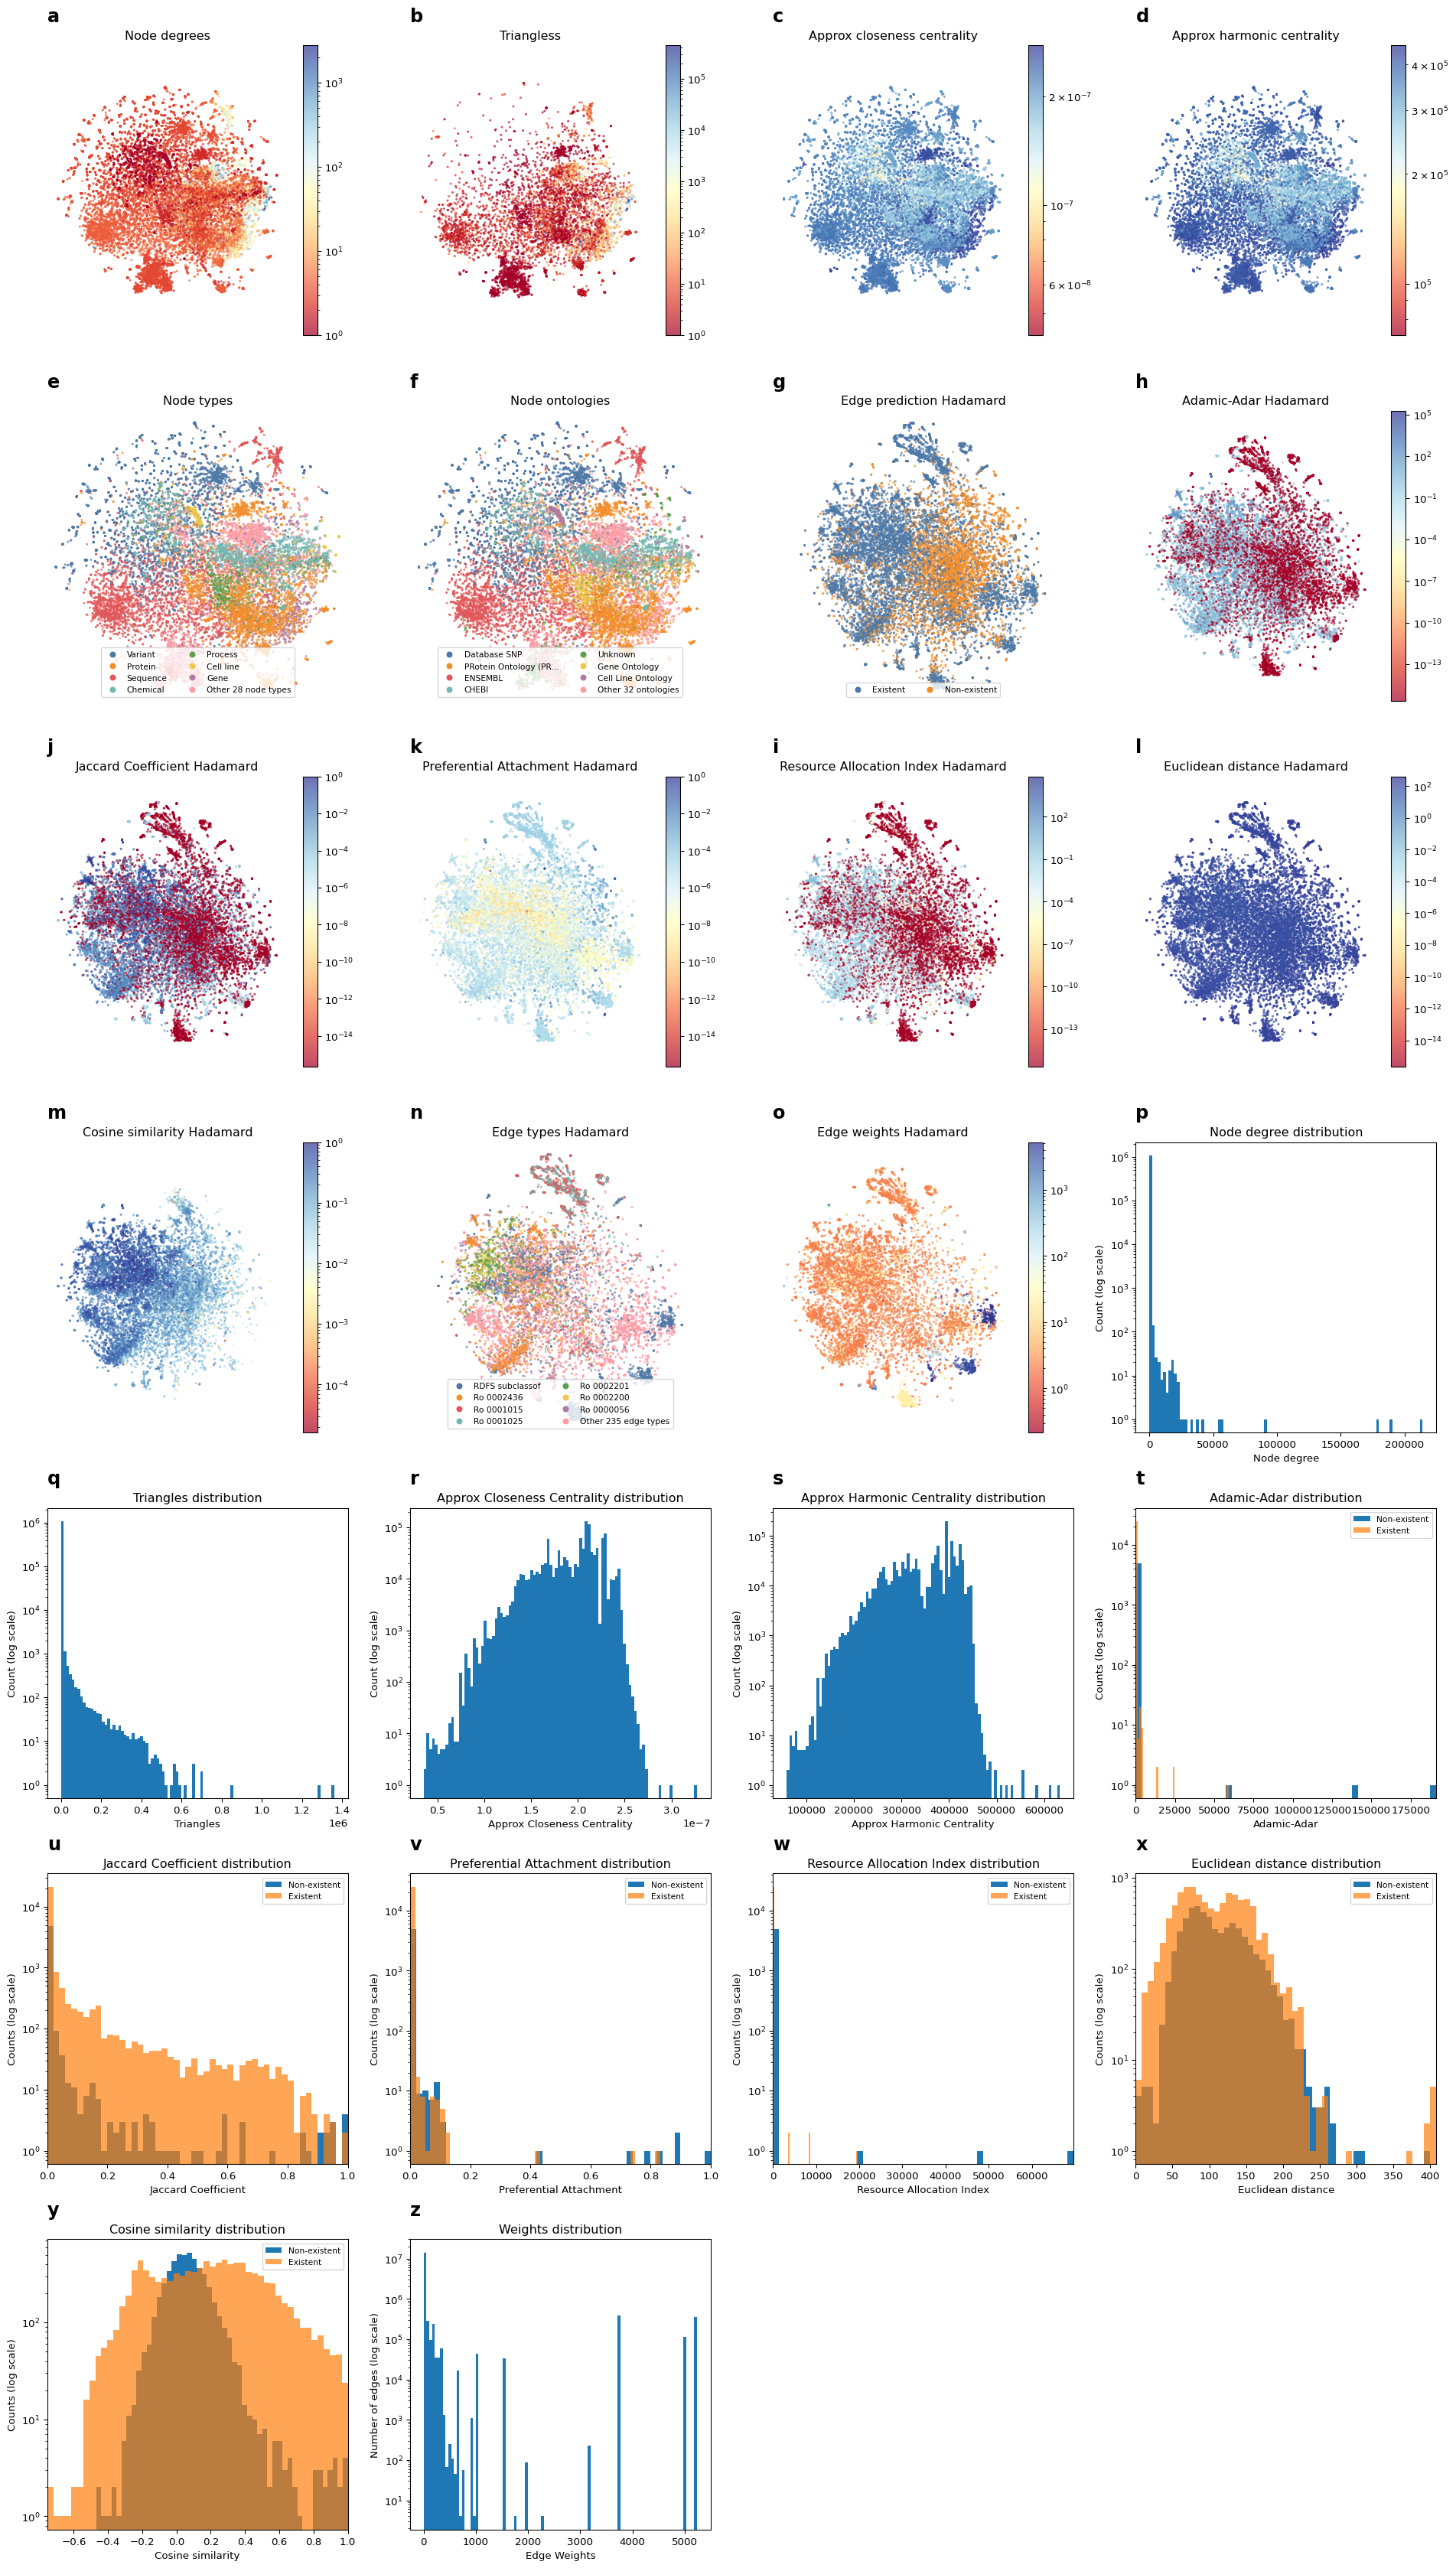

CPU times: user 14min 36s, sys: 11 s, total: 14min 47s
Wall time: 1min 43s


In [23]:
%%time
fig = vis_had.fit_and_plot_all(node2vec_cbow_embedding_default)

In [26]:
import matplotlib.pyplot as plt

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 20000 samples in 0.001s...
[t-SNE] Computed neighbors for 20000 samples in 0.383s...
[t-SNE] Computed conditional probabilities for sample 1000 / 20000
[t-SNE] Computed conditional probabilities for sample 2000 / 20000
[t-SNE] Computed conditional probabilities for sample 3000 / 20000
[t-SNE] Computed conditional probabilities for sample 4000 / 20000
[t-SNE] Computed conditional probabilities for sample 5000 / 20000
[t-SNE] Computed conditional probabilities for sample 6000 / 20000
[t-SNE] Computed conditional probabilities for sample 7000 / 20000
[t-SNE] Computed conditional probabilities for sample 8000 / 20000
[t-SNE] Computed conditional probabilities for sample 9000 / 20000
[t-SNE] Computed conditional probabilities for sample 10000 / 20000
[t-SNE] Computed conditional probabilities for sample 11000 / 20000
[t-SNE] Computed conditional probabilities for sample 12000 / 20000
[t-SNE] Computed conditional probabilities for sam

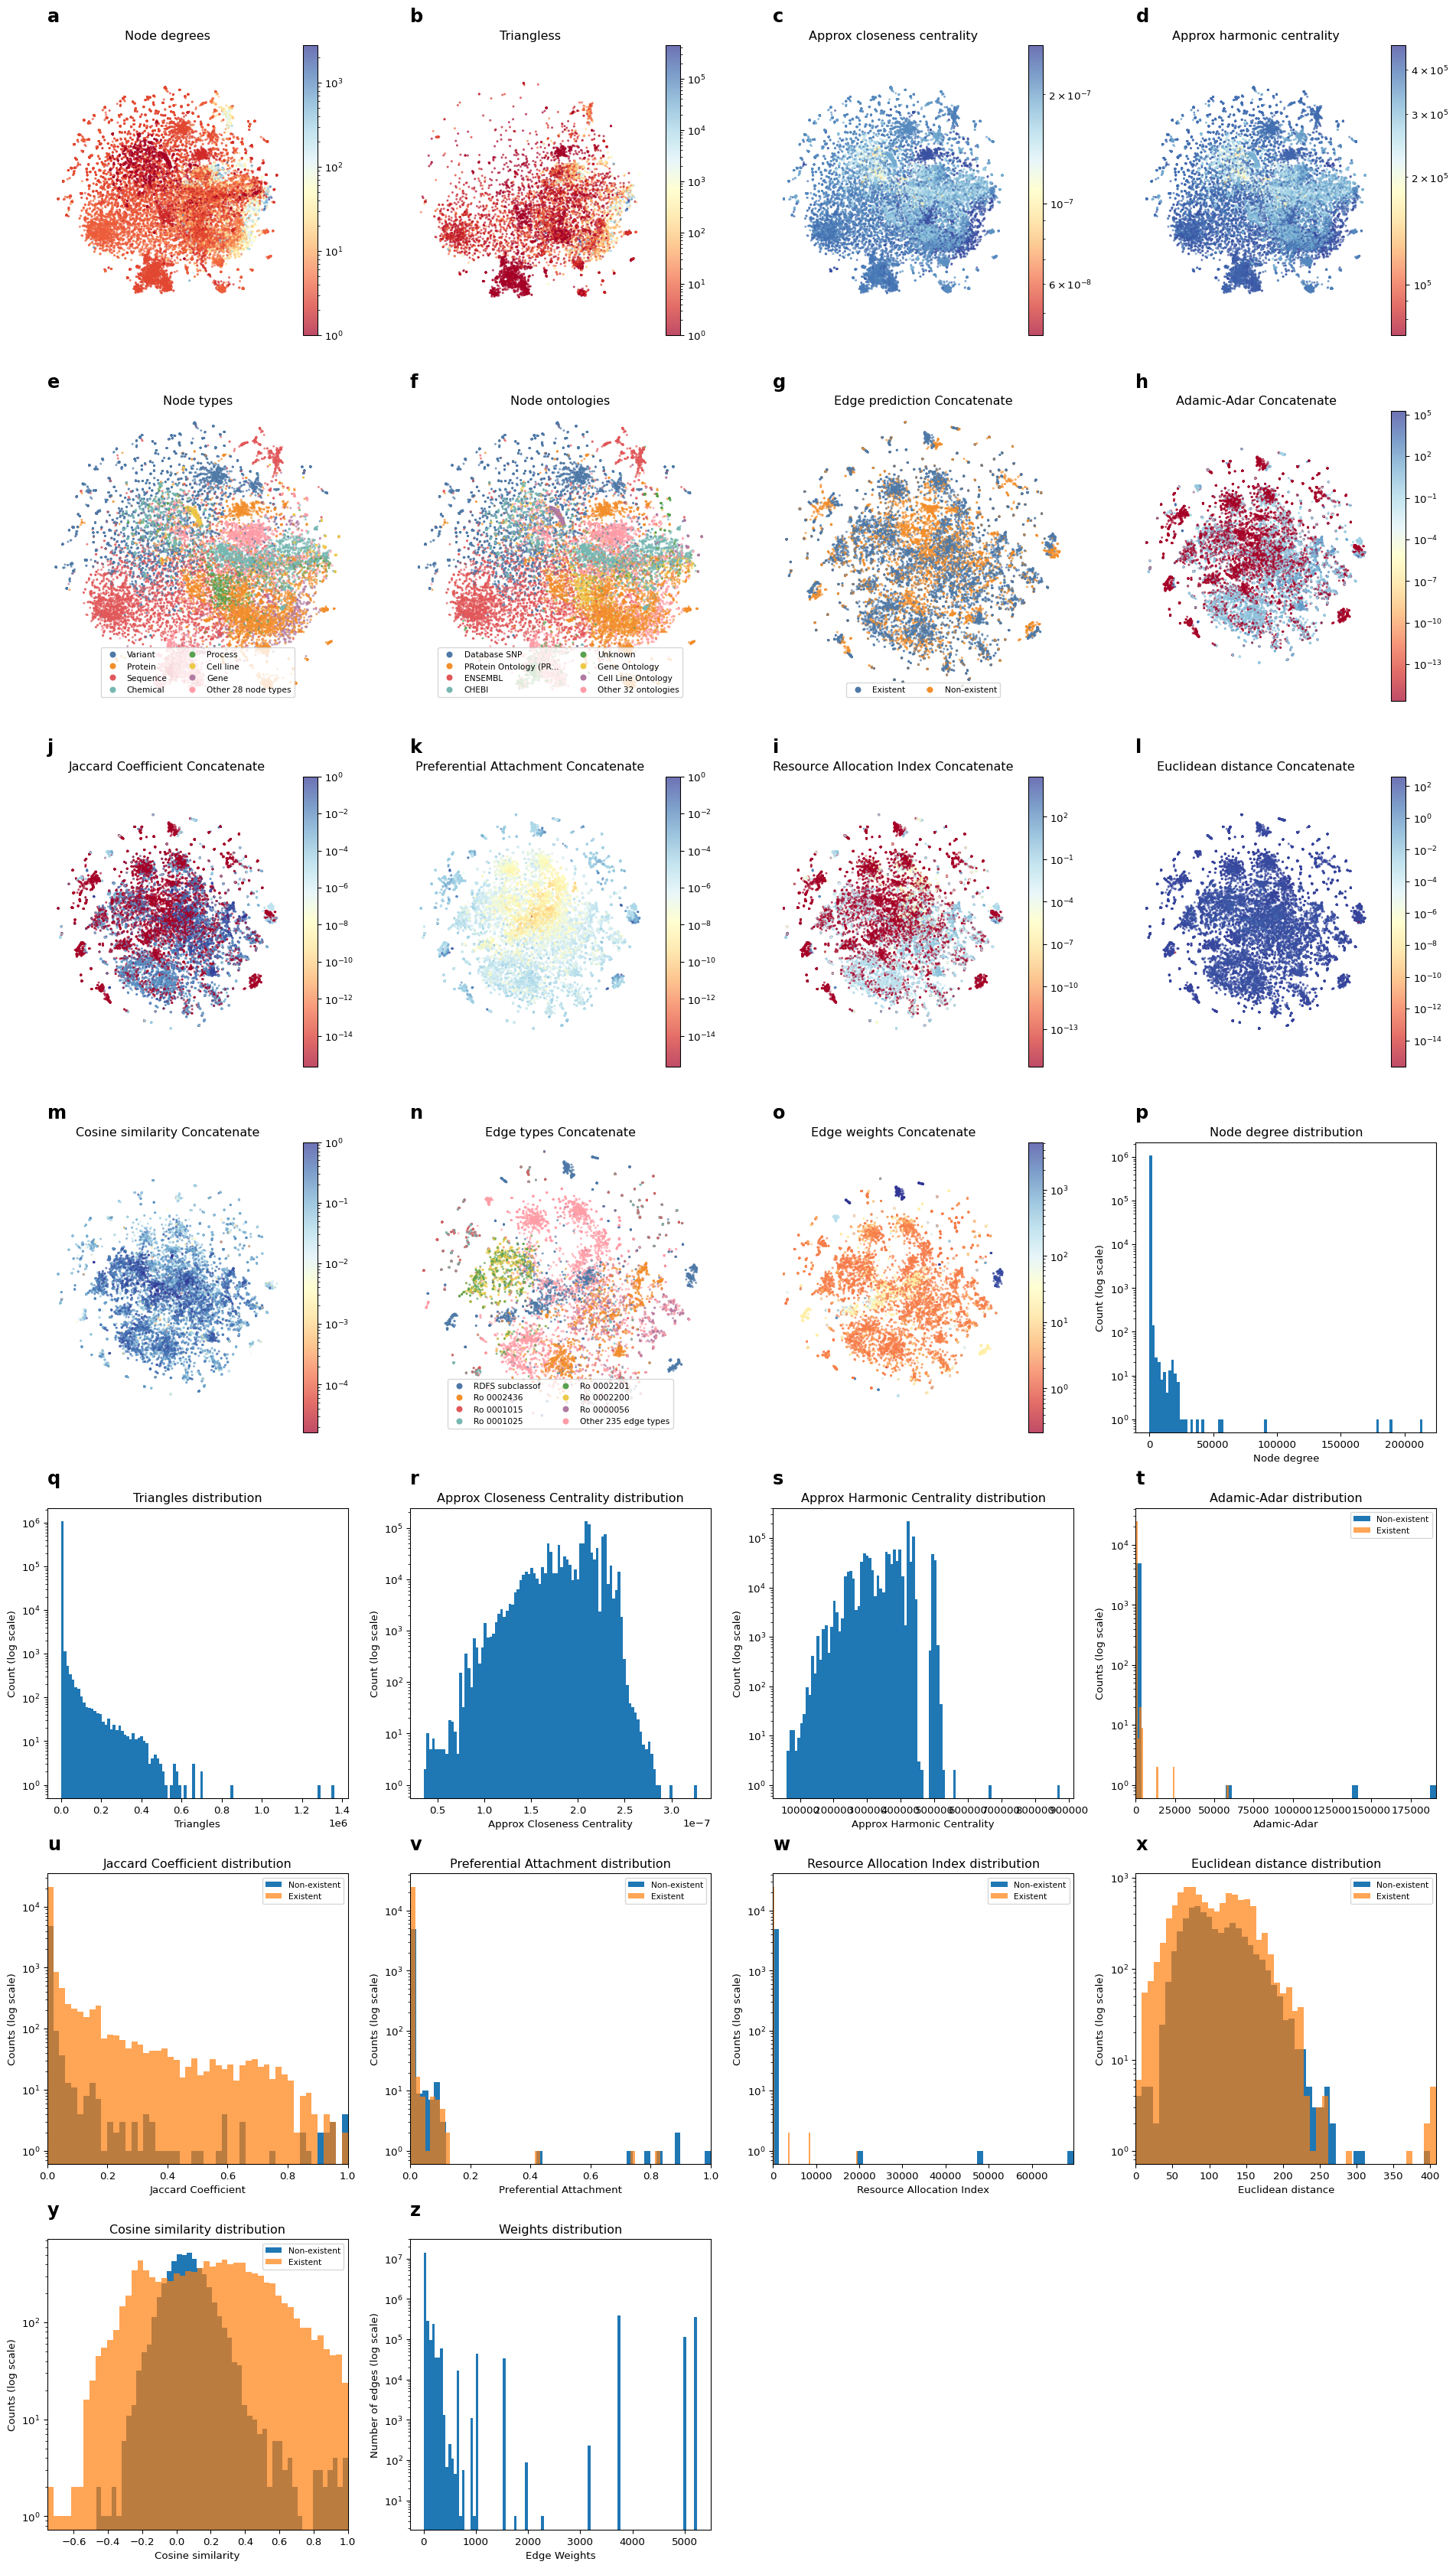

CPU times: user 14min 14s, sys: 15.7 s, total: 14min 29s
Wall time: 1min 46s


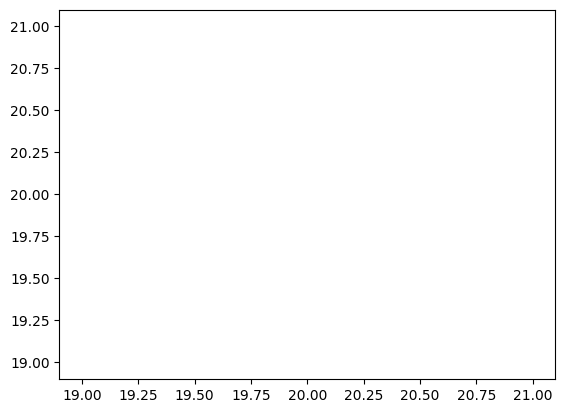

In [29]:
%%time
fig = plt.plot(20,20)
vis_conc = GraphVisualizer(npkg_default, verbose=True, edge_embedding_methods="Concatenate", rotate=False)
fig = vis_conc.fit_and_plot_all(node2vec_cbow_embedding_default)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 20000 samples in 0.001s...
[t-SNE] Computed neighbors for 20000 samples in 0.363s...
[t-SNE] Computed conditional probabilities for sample 1000 / 20000
[t-SNE] Computed conditional probabilities for sample 2000 / 20000
[t-SNE] Computed conditional probabilities for sample 3000 / 20000
[t-SNE] Computed conditional probabilities for sample 4000 / 20000
[t-SNE] Computed conditional probabilities for sample 5000 / 20000
[t-SNE] Computed conditional probabilities for sample 6000 / 20000
[t-SNE] Computed conditional probabilities for sample 7000 / 20000
[t-SNE] Computed conditional probabilities for sample 8000 / 20000
[t-SNE] Computed conditional probabilities for sample 9000 / 20000
[t-SNE] Computed conditional probabilities for sample 10000 / 20000
[t-SNE] Computed conditional probabilities for sample 11000 / 20000
[t-SNE] Computed conditional probabilities for sample 12000 / 20000
[t-SNE] Computed conditional probabilities for sam

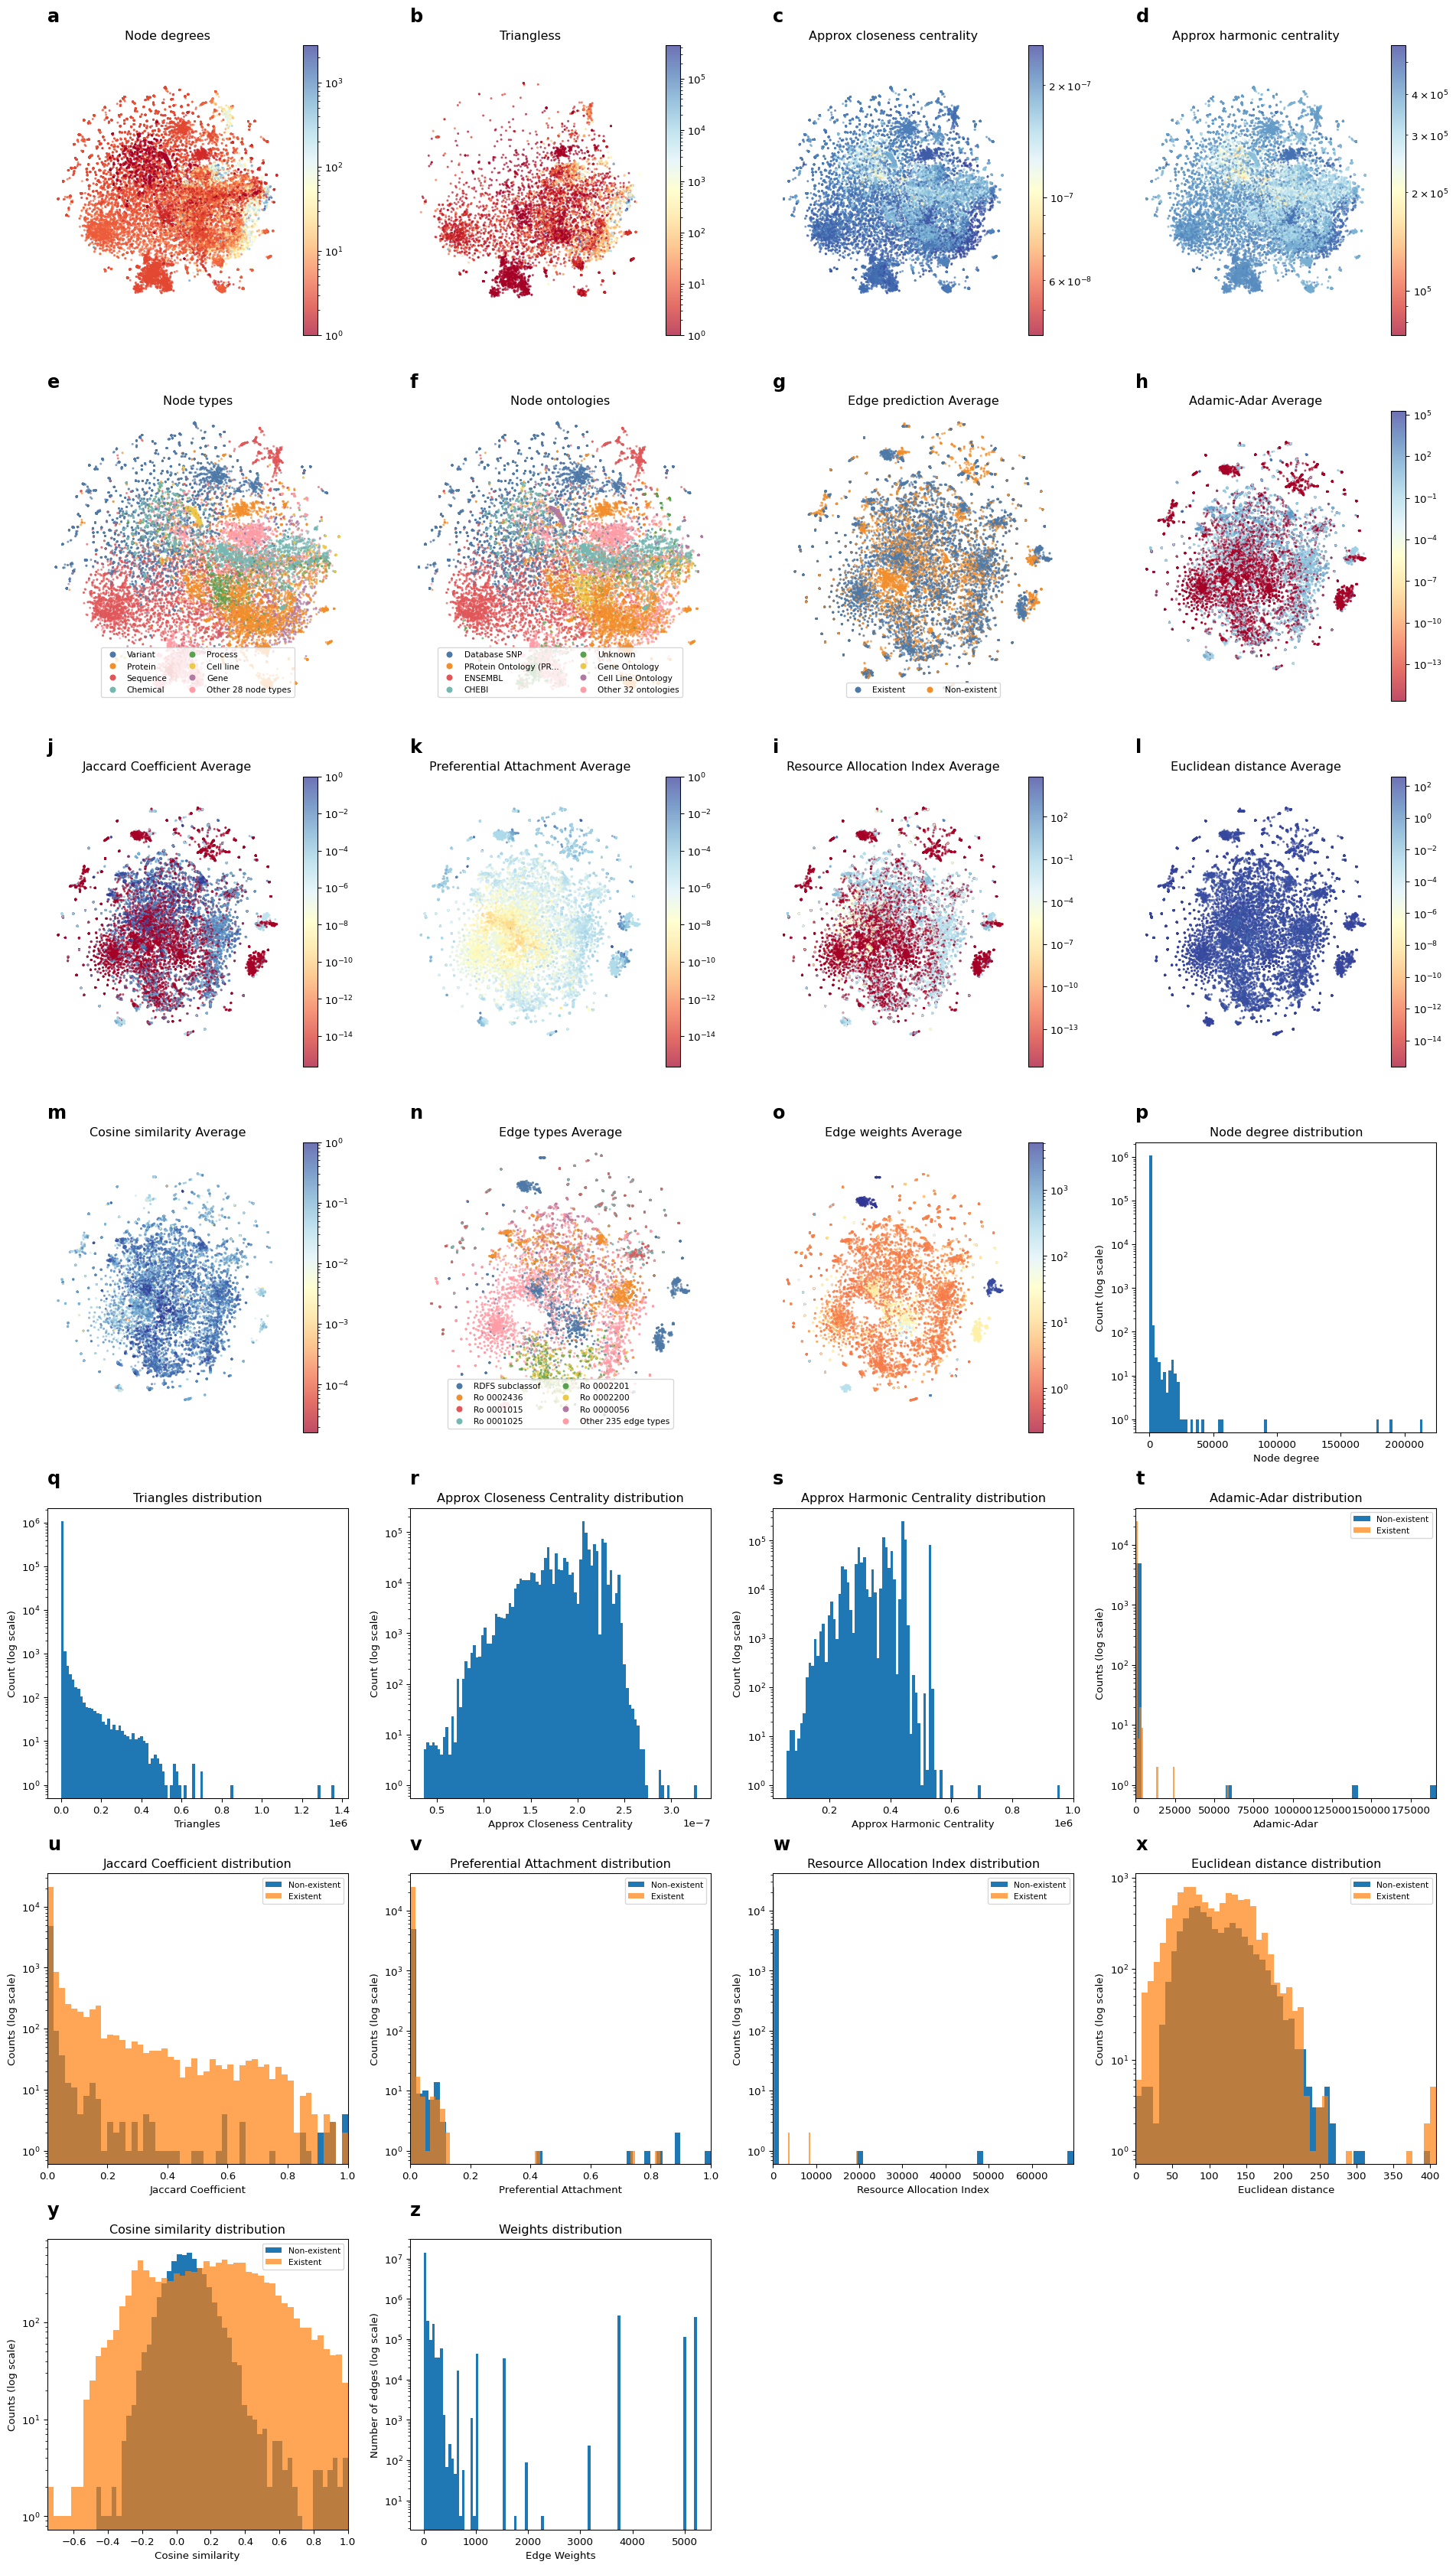

CPU times: user 14min 3s, sys: 15.6 s, total: 14min 19s
Wall time: 1min 46s


In [31]:
%%time
vis_mean = GraphVisualizer(npkg_default, verbose=True, edge_embedding_methods="Average", rotate=False)
vis_mean.fit_and_plot_all(node2vec_cbow_embedding_default)

### Visualize test embeddings for edge prediction (aggregation methods)

In [33]:
vis_test = GraphVisualizer(
    graph=test_default,
    support=npkg_default,
    edge_embedding_methods="Hadamard",
    verbose=True,
    decomposition_kwargs=dict(metric="euclidean"),
    automatically_display_on_notebooks=False
)

In [34]:
%%time
vis_test.fit_negative_and_positive_edges(node2vec_cbow_embedding_default)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 15000 samples in 0.001s...
[t-SNE] Computed neighbors for 15000 samples in 0.351s...
[t-SNE] Computed conditional probabilities for sample 1000 / 15000
[t-SNE] Computed conditional probabilities for sample 2000 / 15000
[t-SNE] Computed conditional probabilities for sample 3000 / 15000
[t-SNE] Computed conditional probabilities for sample 4000 / 15000
[t-SNE] Computed conditional probabilities for sample 5000 / 15000
[t-SNE] Computed conditional probabilities for sample 6000 / 15000
[t-SNE] Computed conditional probabilities for sample 7000 / 15000
[t-SNE] Computed conditional probabilities for sample 8000 / 15000
[t-SNE] Computed conditional probabilities for sample 9000 / 15000
[t-SNE] Computed conditional probabilities for sample 10000 / 15000
[t-SNE] Computed conditional probabilities for sample 11000 / 15000
[t-SNE] Computed conditional probabilities for sample 12000 / 15000
[t-SNE] Computed conditional probabilities for sam

In [35]:
import matplotlib.pyplot as plt

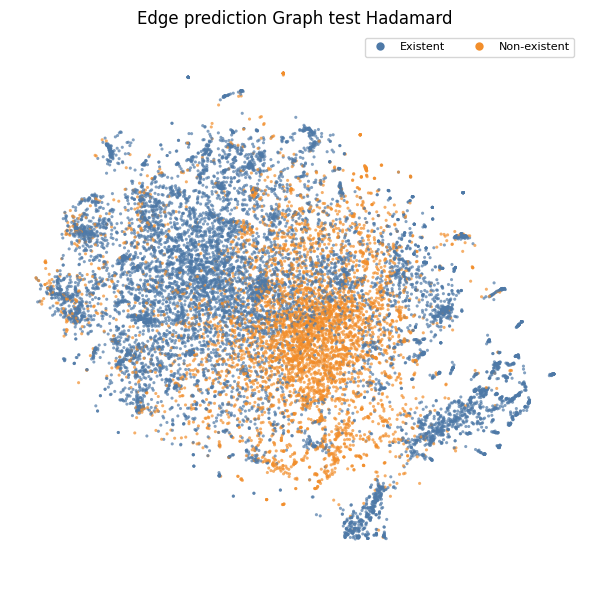

In [36]:
fig, ax = plt.subplots(figsize=(6,6))
vis_test.plot_positive_and_negative_edges(figure=fig, axes=ax)
fig.savefig('images/npkg_node2vec_test_edges.png')
plt.show()

In [38]:
plt.close(fig)

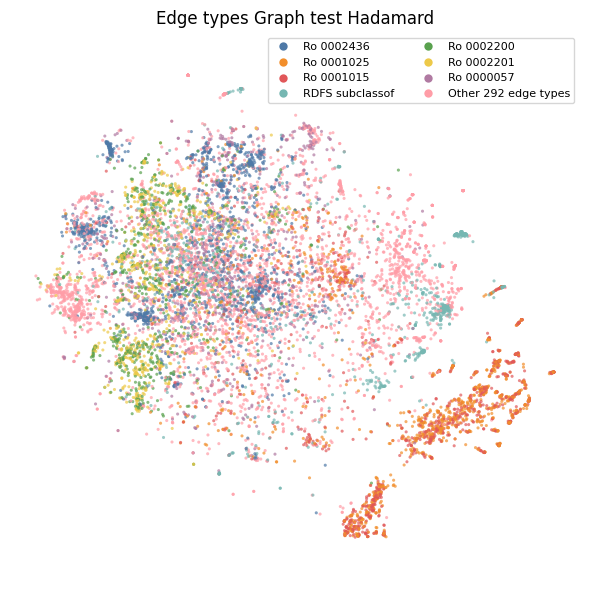

CPU times: user 605 ms, sys: 363 ms, total: 968 ms
Wall time: 615 ms


In [39]:
%%time
fig, ax = plt.subplots(figsize=(6,6))
vis_test.plot_edge_types(figure=fig, axes=ax)
fig.savefig('images/npkg_node2vec_test_edge_types.png')
plt.show()

### Aggregate embeddings - only for multigraph

In [ ]:
aggregate_options = ['sum', 'concatenate', 'average', 'hadamard']

### Setup intrinsic evaluation

In [ ]:
from grape.edge_prediction import MLPEdgePrediction

In [ ]:
edge_feature_options = ['sum', 'hadamard', 'concatenate', 'average']

In [ ]:
model1 = MLPEdgePrediction(
    edge_embedding_methods = "Hadamard"
)

In [ ]:
model1.fit(
    graph = train_default,
    node_features = node2vec_skipgram_embedding_default,
    #edge_features
)

In [ ]:
%%time
# A perfect model should correctly predict the existance
# of all of these edges.
model.predict_proba(
    graph=test,
    node_features=train_embedding.get_node_embedding_from_index,
    return_predictions_dataframe=True
)


In [ ]:
%%time
# A perfect model should correctly predict the non-existance
# of all of these edges.
model.predict_proba(
    graph=graph.sample_negative_graph(number_of_negative_samples=test.get_number_of_edges()),
    node_features=train_embedding.get_node_embedding_from_index,
    return_predictions_dataframe=True
)

In [ ]:
##evaluate model and get metrics

In [ ]:
model1.dump(path='json or pkl')